# PHOBERT TRUE ABSA V4.0: PHÁT HIỆN ĐA KHÍA CẠNH & CỰC TÍNH (5 × 4)
- Dự đoán đồng thời 5 đầu `absa_0..absa_4`, mỗi đầu 4 trạng thái: `0=None, 1=Negative, 2=Neutral, 3=Positive`.
- Chống tràn thông tin với `MAX_LEN = 128`, nhãn xung đột nội bộ theo luật `Neg > Neu > Pos`, và hiệu chỉnh nhiệt độ riêng cho 5 đầu (`T_0..T_4`) trên `df_calib`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!mkdir -p models/phobert_absa_v4 && unzip -o "/content/drive/MyDrive/phobert_absa_outputs_v4.zip" -d models/phobert_absa_v4/
!ls -lh models/phobert_absa_v4/phobert_absa_best.pt

unzip:  cannot find or open /content/drive/MyDrive/phobert_absa_outputs_v4.zip, /content/drive/MyDrive/phobert_absa_outputs_v4.zip.zip or /content/drive/MyDrive/phobert_absa_outputs_v4.zip.ZIP.
ls: cannot access 'models/phobert_absa_v4/phobert_absa_best.pt': No such file or directory


In [4]:
import os, sys
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import importlib.util, subprocess
    if importlib.util.find_spec('pyvi') is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'pyvi'])

if IN_COLAB and not os.path.exists('src'):
    import zipfile
    from google.colab import files
    print('Upload src_and_data_v4.zip (chứa src/ + data/processed/ + models/baseline_absa_metrics.json)...')
    uploaded = files.upload()
    for fn in uploaded:
        if fn.endswith('.zip'):
            with zipfile.ZipFile(fn, 'r') as zf:
                zf.extractall('.')

ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print('ROOT:', ROOT)


Upload src_and_data_v4.zip (chứa src/ + data/processed/ + models/baseline_absa_metrics.json)...


Saving src_and_data_v4.zip to src_and_data_v4.zip
ROOT: /content


In [5]:
import json, random, zipfile, joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoConfig, AutoTokenizer, get_linear_schedule_with_warmup
from sklearn.metrics import classification_report

from src.labels import (
    ABSA_COLS, ABSA_STATES, ABSA_STATE_VI, ASPECT_GROUPS,
    classify_silent_complaint_levels, compute_absa_metrics,
    compute_paired_bootstrap_ci, derive_overall_sentiment,
)
from src.text_cleaner import clean_text, segment_words
from src.modeling import (
    ABSATemperatureScaler, MAX_LEN_ABSA, PII_TOKENS, PhoBertABSA,
    ViSFDDataset, compute_absa_class_weights, dynamic_collate_fn,
    init_semantic_pii_embeddings, split_dev_three_way, tune_absa_calib_threshold,
)

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PROC_DIR = os.path.join(ROOT, 'data', 'processed')
MODEL_DIR = os.path.join(ROOT, 'models')
SAVE_DIR = os.path.join(MODEL_DIR, 'phobert_absa_v4')
os.makedirs(SAVE_DIR, exist_ok=True)
print('IN_COLAB:', IN_COLAB, '| device:', device)
if IN_COLAB and not torch.cuda.is_available():
    print('CANH BAO: Hay chon Runtime -> Change runtime type -> T4 GPU!')


IN_COLAB: True | device: cuda


## 2. NẠP DỮ LIỆU SẠCH VÀ CHIA TẬP DEV 3 PHẦN ĐỘC LẬP

In [6]:
df_train = pd.read_csv(os.path.join(PROC_DIR, 'train_clean.csv'))
df_dev = pd.read_csv(os.path.join(PROC_DIR, 'dev_clean.csv'))
df_test = pd.read_csv(os.path.join(PROC_DIR, 'test_clean.csv'))
df_eyeball, df_calib, df_val = split_dev_three_way(df_dev, random_state=42)
print('Shapes train/eyeball/calib/val/test:', df_train.shape, df_eyeball.shape, df_calib.shape, df_val.shape, df_test.shape)
df_train[['sentence_seg'] + ABSA_COLS + ['has_conflict', 'conflict_with_neg']].head(3)


Shapes train/eyeball/calib/val/test: (7762, 24) (250, 24) (300, 24) (560, 24) (2224, 24)


,sentence_seg,absa_0,absa_1,absa_2,absa_3,absa_4,has_conflict,conflict_with_neg
0,Mới mua máy này Tại thegioididong thốt_nốt cảm...,3,3,3,3,3,False,False
1,Pin kém còn lại miễn chê mua 8 / 3 / 2019 tình...,0,0,1,0,3,False,False
2,Sao lúc gọi điện_thoại màn_hình bị chấm nhỏ nh...,1,0,0,0,0,False,False


## 3. TOKENIZER, KHỞI TẠO EMBEDDING PII VÀ DYNAMIC DATALOADER (MAX_LEN=128)

In [7]:
seed_everything(42)
MODEL_NAME = 'vinai/phobert-base-v2'
tok_src = SAVE_DIR if os.path.exists(os.path.join(SAVE_DIR, 'vocab.txt')) else MODEL_NAME
tokenizer = AutoTokenizer.from_pretrained(tok_src)
DROPOUT = 0.2
if torch.cuda.is_available():
    model = PhoBertABSA(model_name_or_dir=MODEL_NAME, dropout=DROPOUT)
else:
    cfg = AutoConfig.from_pretrained(SAVE_DIR if os.path.exists(os.path.join(SAVE_DIR, 'config.json')) else MODEL_NAME)
    model = PhoBertABSA(config=cfg, dropout=DROPOUT)
init_semantic_pii_embeddings(model.encoder, tokenizer)
model = model.to(device)

sample_seg = segment_words(clean_text('Pin dùng lâu, liên hệ 0901234567 đơn ORD-2024-001'))
print('Tokenized PII check:', tokenizer.tokenize(sample_seg))


config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  540MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Tokenized PII check: ['Pin', 'dùng', 'lâu', ',', 'liên_hệ', '[PHONE]', 'đơn', '[ORDER_ID]']


In [8]:
MAX_LEN = MAX_LEN_ABSA  # 128
train_ds = ViSFDDataset(df_train['sentence_seg'].fillna(''), tokenizer, absa_targets=df_train[ABSA_COLS].values, max_len=MAX_LEN)
eye_ds = ViSFDDataset(df_eyeball['sentence_seg'].fillna(''), tokenizer, absa_targets=df_eyeball[ABSA_COLS].values, max_len=MAX_LEN)
cal_ds = ViSFDDataset(df_calib['sentence_seg'].fillna(''), tokenizer, absa_targets=df_calib[ABSA_COLS].values, max_len=MAX_LEN)
val_ds = ViSFDDataset(df_val['sentence_seg'].fillna(''), tokenizer, absa_targets=df_val[ABSA_COLS].values, max_len=MAX_LEN)
dev_ds = ViSFDDataset(df_dev['sentence_seg'].fillna(''), tokenizer, absa_targets=df_dev[ABSA_COLS].values, max_len=MAX_LEN)
test_ds = ViSFDDataset(df_test['sentence_seg'].fillna(''), tokenizer, absa_targets=df_test[ABSA_COLS].values, max_len=MAX_LEN)

BATCH_SIZE = 32 if torch.cuda.is_available() else 16
collate = lambda b: dynamic_collate_fn(b, pad_id=tokenizer.pad_token_id, max_len=MAX_LEN)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
eye_loader = DataLoader(eye_ds, batch_size=64, shuffle=False, collate_fn=collate)
cal_loader = DataLoader(cal_ds, batch_size=64, shuffle=False, collate_fn=collate)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, collate_fn=collate)
dev_loader = DataLoader(dev_ds, batch_size=64, shuffle=False, collate_fn=collate)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, collate_fn=collate)
b0 = next(iter(train_loader))
b0['input_ids'].shape, b0['absa'].shape


(torch.Size([32, 95]), torch.Size([32, 5]))

## 4. HÀM LOSS 5×4 VÀ CẤU HÌNH HUẤN LUYỆN (LR=3e-5, EPOCHS=6, FP16)

In [9]:
Y_tr_absa = df_train[ABSA_COLS].values
Y_val_absa = df_val[ABSA_COLS].values
Y_te_absa = df_test[ABSA_COLS].values
absa_weights = compute_absa_class_weights(Y_tr_absa, power=0.5).to(device)
loss_fns = [nn.CrossEntropyLoss(weight=absa_weights[j], label_smoothing=0.03) for j in range(5)]

LR = 3e-5
WEIGHT_DECAY = 0.01
EPOCHS = 6
PATIENCE = 2
weights_path = os.path.join(SAVE_DIR, 'phobert_absa_best.pt')
history_path = os.path.join(SAVE_DIR, 'training_history.json')
calib_path = os.path.join(SAVE_DIR, 'calibration.json')

def collect_logits(m, loader):
    m.eval()
    all_logits = []
    with torch.no_grad():
        for b in loader:
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits = m(b['input_ids'].to(device), b['attention_mask'].to(device))
            all_logits.append(logits.float().cpu().numpy())
    return np.concatenate(all_logits, axis=0)
print('ABSA class weights shape:', tuple(absa_weights.shape))


ABSA class weights shape: (5, 4)


## 5. HUẤN LUYỆN TRÊN GPU VỚI REAL EARLY STOPPING

In [10]:
FORCE_RETRAIN = False
if torch.cuda.is_available() and (FORCE_RETRAIN or not os.path.exists(weights_path)):
    no_decay = ['bias', 'LayerNorm.weight', 'LayerNorm.bias']
    opt_groups = [
        {'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], 'weight_decay': WEIGHT_DECAY},
        {'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], 'weight_decay': 0.0},
    ]
    optimizer = torch.optim.AdamW(opt_groups, lr=LR)
    total_steps = len(train_loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    amp_scaler = torch.amp.GradScaler('cuda', enabled=True)
    best_val_f1, wait, history = -1.0, 0, []
    for ep in range(EPOCHS):
        model.train()
        tot_loss = 0.0
        for b in train_loader:
            optimizer.zero_grad()
            y_b = b['absa'].to(device)
            with torch.amp.autocast('cuda', enabled=True):
                logits = model(b['input_ids'].to(device), b['attention_mask'].to(device))
                loss = sum(loss_fns[j](logits[:, j, :], y_b[:, j]) for j in range(5)) / 5.0
            amp_scaler.scale(loss).backward()
            amp_scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            amp_scaler.step(optimizer)
            amp_scaler.update()
            scheduler.step()
            tot_loss += float(loss.item())
        val_logits = collect_logits(model, val_loader)
        val_m = compute_absa_metrics(Y_val_absa, val_logits.argmax(axis=-1))
        val_f1 = val_m['absa_macro_f1']
        if val_f1 > best_val_f1:
            best_val_f1, wait, st = val_f1, 0, 'best_saved'
            torch.save(model.state_dict(), weights_path)
            tokenizer.save_pretrained(SAVE_DIR)
            model.encoder.config.save_pretrained(SAVE_DIR)
        else:
            wait += 1
            st = 'early_stop' if wait >= PATIENCE else f'patience_{wait}'
        row_h = {
            'epoch': ep + 1, 'loss': round(tot_loss / len(train_loader), 4),
            'val_absa_macro_f1': val_f1, 'val_4cls_macro_f1': val_m['mean_4cls_macro_f1'],
            'val_pol_det_f1': val_m['polarity_given_detected_macro_f1'], 'status': st,
        }
        history.append(row_h)
        with open(history_path, 'w', encoding='utf-8') as f:
            json.dump(history, f, indent=2, ensure_ascii=False)
        print(row_h)
        if wait >= PATIENCE:
            print('Early stopping tai epoch:', ep + 1)
            break
else:
    print('Dang tren CPU Local: Hay upload src_and_data_v4.zip va chay NB04 tren Google Colab T4 GPU!')


{'epoch': 1, 'loss': 1.0802, 'val_absa_macro_f1': 0.7389, 'val_4cls_macro_f1': 0.6505, 'val_pol_det_f1': 0.7555, 'status': 'best_saved'}
{'epoch': 2, 'loss': 0.7505, 'val_absa_macro_f1': 0.8033, 'val_4cls_macro_f1': 0.7506, 'val_pol_det_f1': 0.81, 'status': 'best_saved'}
{'epoch': 3, 'loss': 0.6266, 'val_absa_macro_f1': 0.8268, 'val_4cls_macro_f1': 0.7759, 'val_pol_det_f1': 0.8367, 'status': 'best_saved'}
{'epoch': 4, 'loss': 0.5512, 'val_absa_macro_f1': 0.8323, 'val_4cls_macro_f1': 0.7777, 'val_pol_det_f1': 0.837, 'status': 'best_saved'}
{'epoch': 5, 'loss': 0.4977, 'val_absa_macro_f1': 0.8328, 'val_4cls_macro_f1': 0.7798, 'val_pol_det_f1': 0.8301, 'status': 'best_saved'}
{'epoch': 6, 'loss': 0.4671, 'val_absa_macro_f1': 0.8375, 'val_4cls_macro_f1': 0.7859, 'val_pol_det_f1': 0.8388, 'status': 'best_saved'}


In [11]:
if os.path.exists(history_path):
    pd.read_json(history_path)


## 6. HIỆU CHỈNH NHIỆT ĐỘ 5 ĐẦU TRÊN DF_CALIB

In [12]:
if not os.path.exists(weights_path):
    raise FileNotFoundError('Chua co phobert_absa_best.pt! Hay chay NB04 tren Colab GPU.')
cfg_best = AutoConfig.from_pretrained(SAVE_DIR)
if device.type == 'cuda':
    model = PhoBertABSA(config=cfg_best, dropout=DROPOUT)
    if model.encoder.get_input_embeddings().weight.shape[0] != len(tokenizer):
        model.encoder.resize_token_embeddings(len(tokenizer))
    model.load_state_dict(torch.load(weights_path, map_location=device))
    model = model.to(device)
else:
    # CPU it RAM: khoi tao tren meta, mmap weights, gan truc tiep (khong copy)
    with torch.device('meta'):
        model = PhoBertABSA(config=cfg_best, dropout=DROPOUT)
        if model.encoder.get_input_embeddings().weight.shape[0] != len(tokenizer):
            model.encoder.resize_token_embeddings(len(tokenizer))
    sd = torch.load(weights_path, map_location='cpu', mmap=True, weights_only=True)
    model.load_state_dict(sd, strict=False, assign=True)
    emb = model.encoder.embeddings
    emb.position_ids = torch.arange(emb.position_embeddings.num_embeddings).unsqueeze(0)
    emb.token_type_ids = torch.zeros(emb.position_ids.shape, dtype=torch.long)
model.eval()

cal_logits = collect_logits(model, cal_loader)
scaler = ABSATemperatureScaler().fit(cal_logits, df_calib[ABSA_COLS].values)
cal_probs = scaler.predict_probs(cal_logits)
calib_info = {**scaler.to_dict(), **tune_absa_calib_threshold(cal_probs, df_calib[ABSA_COLS].values)}
with open(calib_path, 'w', encoding='utf-8') as f:
    json.dump(calib_info, f, indent=2, ensure_ascii=False)
calib_info


{'temps': [0.766772, 0.648832, 0.614807, 0.778183, 0.745168],
 'low_conf_threshold': 0.75,
 'calib_review_precision': 0.6101,
 'calib_review_fpr': 0.3899,
 'review_budget': 0.15,
 'review_conf_threshold': 0.5094,
 'calib_budget_precision': 0.7333,
 'calib_budget_error_recall': 0.234}

## 7. PHÂN TÍCH EYEBALL DEV & ĐÁNH GIÁ NIÊM PHONG TEST + PAIRED BOOTSTRAP CI

In [13]:
eye_probs = scaler.predict_probs(collect_logits(model, eye_loader))
eye_pred = eye_probs.argmax(axis=-1)
print('Eyeball ABSA 5x4:', compute_absa_metrics(df_eyeball[ABSA_COLS].values, eye_pred))

val_probs = scaler.predict_probs(collect_logits(model, val_loader))
val_pred = val_probs.argmax(axis=-1)
print('Val Dev ABSA 5x4:', compute_absa_metrics(Y_val_absa, val_pred))

te_probs = scaler.predict_probs(collect_logits(model, test_loader))
te_pred = te_probs.argmax(axis=-1)
te_m_all = compute_absa_metrics(Y_te_absa, te_pred)
conf_mask = df_test['has_conflict'].values.astype(bool)
conf_neg_mask = df_test['conflict_with_neg'].values.astype(bool)
te_m_conf = compute_absa_metrics(Y_te_absa[conf_mask], te_pred[conf_mask])
te_m_conf_neg = compute_absa_metrics(Y_te_absa[conf_neg_mask], te_pred[conf_neg_mask])
print('Test All ABSA 5x4:', te_m_all)
print('Test Conflict (n=' + str(int(conf_mask.sum())) + '):', te_m_conf)
print('Test Conflict+Neg (n=' + str(int(conf_neg_mask.sum())) + '):', te_m_conf_neg)


Eyeball ABSA 5x4: {'absa_micro_f1': 0.8451, 'absa_macro_f1': 0.8482, 'mean_4cls_macro_f1': 0.7801, 'per_aspect_4cls_f1': [0.6568, 0.8444, 0.8197, 0.8562, 0.7232], 'polarity_given_detected_macro_f1': 0.834, 'majority_4cls_macro_f1': 0.1705, 'all1_presence_macro_f1': 0.6702}
Val Dev ABSA 5x4: {'absa_micro_f1': 0.8444, 'absa_macro_f1': 0.8375, 'mean_4cls_macro_f1': 0.7859, 'per_aspect_4cls_f1': [0.766, 0.759, 0.8216, 0.8315, 0.7516], 'polarity_given_detected_macro_f1': 0.8388, 'majority_4cls_macro_f1': 0.1701, 'all1_presence_macro_f1': 0.6783}
Test All ABSA 5x4: {'absa_micro_f1': 0.8405, 'absa_macro_f1': 0.841, 'mean_4cls_macro_f1': 0.7924, 'per_aspect_4cls_f1': [0.7592, 0.8335, 0.8088, 0.8235, 0.737], 'polarity_given_detected_macro_f1': 0.8358, 'majority_4cls_macro_f1': 0.1693, 'all1_presence_macro_f1': 0.6789}
Test Conflict (n=286): {'absa_micro_f1': 0.7455, 'absa_macro_f1': 0.75, 'mean_4cls_macro_f1': 0.7361, 'per_aspect_4cls_f1': [0.6991, 0.7736, 0.7978, 0.74, 0.6701], 'polarity_given

In [14]:
for j, grp in enumerate(ASPECT_GROUPS):
    print(f'=== {grp} (absa_{j}) ===')
    print(classification_report(Y_te_absa[:, j], te_pred[:, j], labels=[0, 1, 2, 3], target_names=ABSA_STATES, digits=4, zero_division=0))


=== PERF_FEAT (absa_0) ===
              precision    recall  f1-score   support

        None     0.9085    0.8765    0.8922       680
    Negative     0.8592    0.9012    0.8797       779
     Neutral     0.4364    0.3265    0.3735       147
    Positive     0.8752    0.9078    0.8912       618

    accuracy                         0.8575      2224
   macro avg     0.7698    0.7530    0.7592      2224
weighted avg     0.8508    0.8575    0.8533      2224

=== SCREEN_CAM (absa_1) ===
              precision    recall  f1-score   support

        None     0.9812    0.9586    0.9698      1474
    Negative     0.7967    0.8819    0.8371       271
     Neutral     0.6053    0.5897    0.5974        78
    Positive     0.9216    0.9377    0.9295       401

    accuracy                         0.9326      2224
   macro avg     0.8262    0.8420    0.8335      2224
weighted avg     0.9348    0.9326    0.9333      2224

=== BATTERY (absa_2) ===
              precision    recall  f1-score   supp

## 7b. PHÂN TÍCH LỖI PHOBERT V4: CONFUSION MATRIX 4×4 & CÂU SAI PRICE_SER NEGATIVE
- Hàng = nhãn thật, cột = dự đoán. Chú ý Neutral ↔ Positive/Negative.
- **Hạn chế:** Neutral chỉ có 78–147 mẫu/khía cạnh trong test (trừ PRICE_SER 344), F1 Neutral 0.33–0.79 kéo `mean_4cls_macro_f1` xuống; với bài toán khiếu nại, F1 Negative (0.71–0.88) mới là chỉ số chính.


PERF_FEAT 
 [[596  48   4  32]
 [ 27 702  35  15]
 [ 11  55  48  33]
 [ 22  12  23 561]]
SCREEN_CAM 
 [[1413   39    4   18]
 [  19  239   11    2]
 [   0   20   46   12]
 [   8    2   15  376]]
BATTERY 
 [[1161   23    8   18]
 [   6  330   25    7]
 [   3   19   48   22]
 [   4   13   31  506]]
PRICE_SER 
 [[1120   53   26   26]
 [  29  178   11   13]
 [  20   27  262   35]
 [  18    6   24  376]]
DESIGN_GEN 
 [[ 487   91   11   75]
 [  46  298   13   16]
 [   4   20   52   29]
 [  43   16   23 1000]]


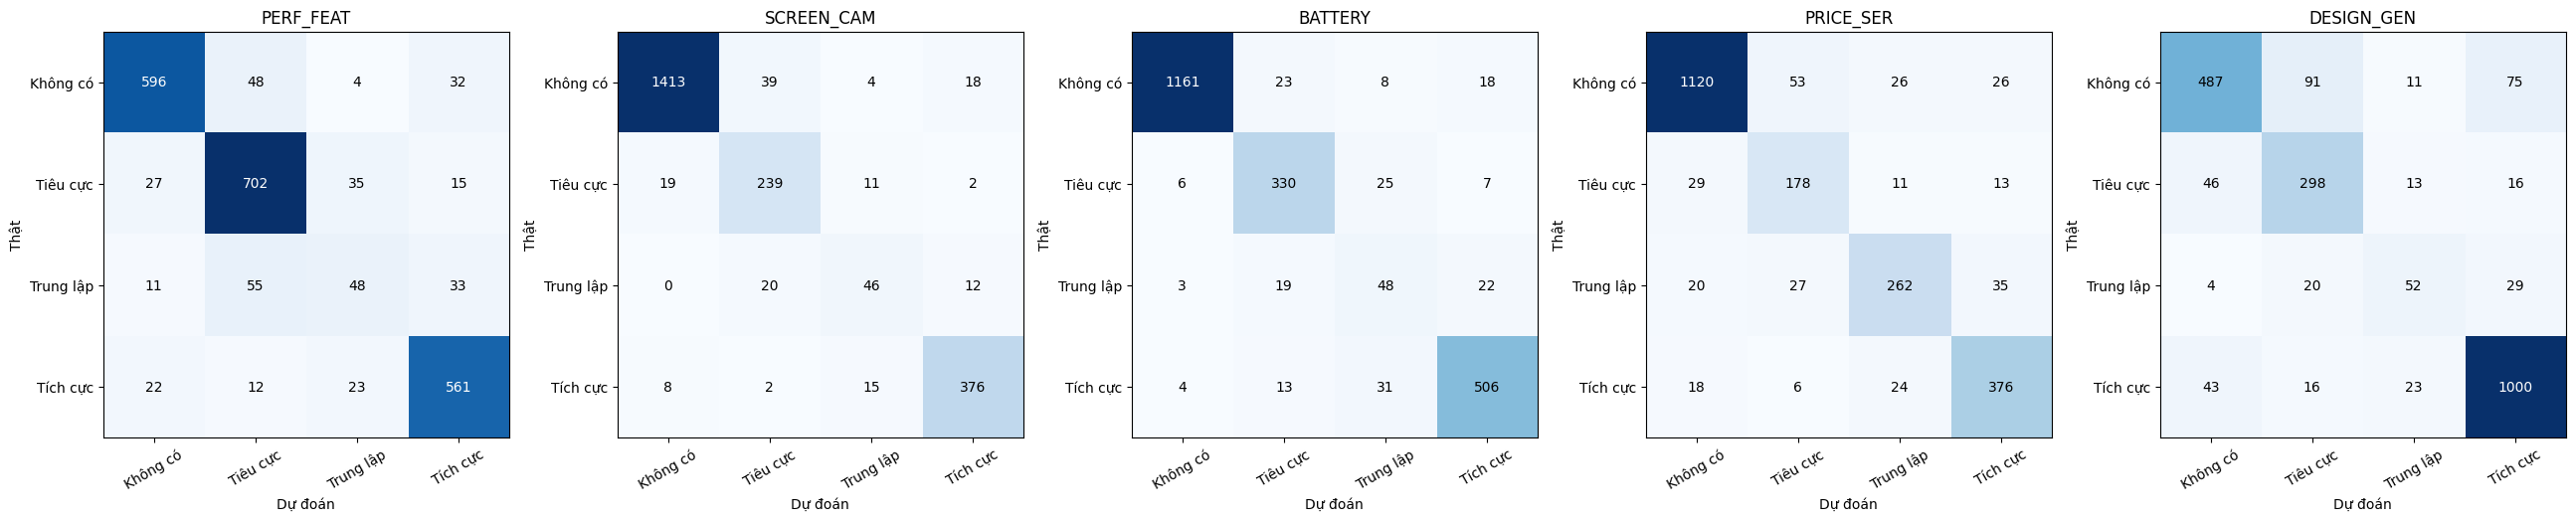

In [15]:
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
FIG_DIR = os.path.join(ROOT, 'reports', 'figures'); os.makedirs(FIG_DIR, exist_ok=True)
fig, axes = plt.subplots(1, 5, figsize=(26, 5))
for j, (grp, ax) in enumerate(zip(ASPECT_GROUPS, axes)):
    cm = confusion_matrix(Y_te_absa[:, j], te_pred[:, j], labels=[0, 1, 2, 3])
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(4)); ax.set_yticks(range(4))
    ax.set_xticklabels(ABSA_STATE_VI, rotation=30); ax.set_yticklabels(ABSA_STATE_VI)
    ax.set_title(grp); ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thật')
    for a in range(4):
        for b in range(4):
            ax.text(b, a, cm[a, b], ha='center', va='center', color='white' if cm[a, b] > cm.max() / 2 else 'black')
    print(grp, '\n', cm)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'fig_absa_v4_confusion.png'), dpi=150); plt.show()


In [16]:
# ~10 cau sai: PRICE_SER (absa_3), that = Negative (1) nhung model doan khac
pd.set_option('display.max_colwidth', 160)
m_bad = (Y_te_absa[:, 3] == 1) & (te_pred[:, 3] != 1)
bad = df_test[m_bad].copy()
bad['pred'] = [ABSA_STATE_VI[int(v)] for v in te_pred[m_bad, 3]]
print(f'PRICE_SER Negative bi bo sot/doan sai: {len(bad)} / {int((Y_te_absa[:, 3] == 1).sum())}')
bad[['sentence_clean', 'n_star', 'pred']].head(10)


PRICE_SER Negative bi bo sot/doan sai: 53 / 231


,sentence_clean,n_star,pred
174,Chụp hình xấu quá. Tầm giá này nên mua của Oppo hoặc Samsung thì hơn. So với nova 3i thì cũng thua,1,Trung lập
328,"Sản phẩm này là TỆ nhất trong dòng samsung. Mua bữa 7/7/2020 đến 8/7/2020 . Tự đơ máy hoặc tắt máy cở 10 lần, còn tự động khởi động lại thì liên tục. Nếu đe...",1,Tích cực
362,"Ưu điểm: mượt, pin trâu. Hạn chế: camera chụp bình thường dù tới 4 camera, độ sáng màn hình yếu, đèn led hơi tối, không được trang bị củ sạc 18w như quảng c...",4,Không có
373,Mới mua hôm qua về.nhìn chung cảm giác cầm nắm cũng khá nặng và đầm tay.Nhưng máy mới mua về mình sạc qua đêm từ 20h - 7h.sáng mai mở nguồn lên chưa dùng gì...,2,Không có
383,"mua được hơn 1 tuần, xài ổn chơi game nhẹ thì ok pin cực kì trâu 4000 mà như 4200 4500, mặc dù bị nhân viên lừa mua máy này nhưng thấy ok ban đầu dự định mu...",4,Tích cực
412,Mình mới mua điện thoại ngày 19/01/2020. Về kiểm tra thì sức khỏe pin chỉ còn 93%. Cho hỏi cái này là điện thoại nào cũng vậy hay là mình mua hàng trong tủ ...,4,Không có
414,Samsung galaxy A71 Ram 8GB mà chơi game liên quân lag quá bật fps cao mà chỉ 48-49 thôi pubg cũng vậy nữa uống số tiền mình bỏ ra mua,4,Trung lập
425,Có nhờ bà chị mua con này để xài . xài 4 ngày cảm giác như sau . camera thực sự kém xa so với thời mình xài j7+ của samsung . chơi game cũng không mượt bằng...,4,Không có
458,3790 được không xiaomi ơi. Không em mua vsmart live ạ. Hàng viêt nam giá việt nam.,4,Tích cực
633,Có anh em nào bị như mình không note 10+ ban ngày vân tay rất nhậy ban đêm thì không nhạy chạm 3 lần mới được .chán ss,3,Không có


In [17]:
base_csv = os.path.join(PROC_DIR, 'test_pred_baseline.csv')
boot_ci = None
base_te_metrics = None
if os.path.exists(base_csv):
    dfb = pd.read_csv(base_csv)
    base_pred_cols = [f'pred_absa_{j}' for j in range(5)]
    if all(c in dfb.columns for c in base_pred_cols):
        base_te_pred = dfb[base_pred_cols].values.astype(int)
        base_te_metrics = compute_absa_metrics(Y_te_absa, base_te_pred)
        boot_ci = compute_paired_bootstrap_ci(
            Y_te_absa, te_pred, base_te_pred, metric_key='absa_macro_f1', n_boot=1000, seed=42
        )
        print('Baseline 5x4 Test:', base_te_metrics)
        print('Paired Bootstrap CI (PhoBERT - Baseline absa_macro_f1):', boot_ci)


Baseline 5x4 Test: {'absa_micro_f1': 0.7576, 'absa_macro_f1': 0.7556, 'mean_4cls_macro_f1': 0.6895, 'per_aspect_4cls_f1': [0.6427, 0.7309, 0.7251, 0.7421, 0.6068], 'polarity_given_detected_macro_f1': 0.7854, 'majority_4cls_macro_f1': 0.1693, 'all1_presence_macro_f1': 0.6789}
Paired Bootstrap CI (PhoBERT - Baseline absa_macro_f1): {'metric': 'absa_macro_f1', 'n_boot': 1000, 'a_mean': 0.841, 'a_ci95': [0.8311, 0.8504], 'b_mean': 0.7553, 'b_ci95': [0.7442, 0.7657], 'diff_mean': 0.0857, 'diff_ci95': [0.0757, 0.0954]}


## 8. XUẤT DỰ ĐOÁN, PHÂN BỐ MỨC ĐỘ KHIẾU NẠI NGẦM & ĐÓNG GÓI OUTPUT V4

In [18]:
# Nguong theo ngan sach review (15%) da tune tren df_calib o muc 6
conf_th = calib_info['review_conf_threshold']
dev_probs = scaler.predict_probs(collect_logits(model, dev_loader))
dev_pred = dev_probs.argmax(axis=-1)
dev_pred_path = os.path.join(PROC_DIR, 'dev_pred_phobert.csv')
test_pred_path = os.path.join(PROC_DIR, 'test_pred_phobert.csv')

for df_src, probs_a, pred_a, out_p in [
    (df_dev, dev_probs, dev_pred, dev_pred_path),
    (df_test, te_probs, te_pred, test_pred_path),
]:
    df_o = df_src.copy()
    max_c = probs_a.max(axis=-1)
    for j in range(5):
        df_o[f'pred_absa_{j}'] = pred_a[:, j]
        df_o[f'absa_conf_{j}'] = np.round(max_c[:, j], 4)
    df_o['pred_absa_derived_sent'] = derive_overall_sentiment(pred_a)
    df_o['pred_sentiment'] = df_o['pred_absa_derived_sent']
    df_o['min_aspect_conf'] = np.round(max_c.min(axis=-1), 4)
    cnt_neg, levels, is_hidden_high = classify_silent_complaint_levels(df_o['n_star'].values, pred_a)
    df_o['So_Khia_Canh_Tieu_Cuc'] = cnt_neg
    df_o['Muc_Do_Khieu_Nai_Ngam'] = levels
    df_o['Khieu_Nai_Ngam_4_5_Sao'] = is_hidden_high
    df_o['needs_review'] = ((df_o['min_aspect_conf'] < conf_th) | df_o['is_no_content'].astype(bool)).astype(bool)
    df_o.to_csv(out_p, index=False, encoding='utf-8-sig')

df_te_chk = pd.read_csv(test_pred_path, keep_default_na=False)
dist_test = df_te_chk['Muc_Do_Khieu_Nai_Ngam'].value_counts().to_dict()
print('Test Muc_Do_Khieu_Nai_Ngam distribution:', dist_test)
is_45 = df_te_chk['n_star'] >= 4
print('4-5 sao breakdown (% trong 4-5*):', (df_te_chk.loc[is_45, 'Muc_Do_Khieu_Nai_Ngam'].value_counts(normalize=True) * 100).round(2).to_dict())
print('needs_review count:', df_te_chk['needs_review'].value_counts().to_dict())

# Tren test: ty le co thuc te + precision/recall bat loi (loi = sai it nhat 1 trong 5 khia canh)
_err = (te_pred != Y_te_absa).any(axis=1)
_nr = df_te_chk['needs_review'].values
review_stats = {
    'review_budget': calib_info['review_budget'], 'review_conf_threshold': conf_th,
    'test_flag_rate': round(float(_nr.mean()), 4),
    'test_error_rate': round(float(_err.mean()), 4),
    'test_precision': round(float((_nr & _err).sum() / max(_nr.sum(), 1)), 4),
    'test_error_recall': round(float((_nr & _err).sum() / max(_err.sum(), 1)), 4),
}
print('REVIEW (test):', review_stats)


Test Muc_Do_Khieu_Nai_Ngam distribution: {'Không': 947, 'N/A': 827, 'Nhẹ': 242, 'Cao': 208}
4-5 sao breakdown (% trong 4-5*): {'Không': 67.79, 'Nhẹ': 17.32, 'Cao': 14.89}
needs_review count: {False: 1875, True: 349}
REVIEW (test): {'review_budget': 0.15, 'review_conf_threshold': 0.5094, 'test_flag_rate': 0.1569, 'test_error_rate': 0.4433, 'test_precision': 0.745, 'test_error_recall': 0.2637}


In [19]:
meta = {
    'version': 'v4.0_true_absa_5x4',
    'dataset': f'UIT-ViSFD E-Commerce ({len(df_train)} train / {len(df_eyeball)} eyeball / {len(df_calib)} calib / {len(df_val)} val / {len(df_test)} test)',
    'max_len': MAX_LEN,
    'calibration': calib_info,
    'needs_review_test': review_stats,
    'note_seed': 'Paired bootstrap CI chi phan anh dao dong mau test (1 seed huan luyen = 42).',
    'phobert_absa_v4': {
        'backbone': MODEL_NAME,
        **te_m_all,
        'conflict_absa_macro_f1': te_m_conf['absa_macro_f1'],
        'conflict_with_neg_absa_macro_f1': te_m_conf_neg['absa_macro_f1'],
        'paired_bootstrap_ci_vs_baseline': boot_ci,
        'silent_complaint_dist_test': dist_test,
    },
}
if base_te_metrics is not None:
    meta['baseline_absa_v4'] = base_te_metrics
    base_meta_p = os.path.join(MODEL_DIR, 'baseline_absa_metrics.json')
    if os.path.exists(base_meta_p):
        meta['baseline_absa_v4']['family'] = json.load(open(base_meta_p, encoding='utf-8')).get('family')
meta_path = os.path.join(MODEL_DIR, 'model_metadata.json')
with open(meta_path, 'w', encoding='utf-8') as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)
print(json.dumps(meta, indent=2, ensure_ascii=False))


{
  "version": "v4.0_true_absa_5x4",
  "dataset": "UIT-ViSFD E-Commerce (7762 train / 250 eyeball / 300 calib / 560 val / 2224 test)",
  "max_len": 128,
  "calibration": {
    "temps": [
      0.766772,
      0.648832,
      0.614807,
      0.778183,
      0.745168
    ],
    "low_conf_threshold": 0.75,
    "calib_review_precision": 0.6101,
    "calib_review_fpr": 0.3899,
    "review_budget": 0.15,
    "review_conf_threshold": 0.5094,
    "calib_budget_precision": 0.7333,
    "calib_budget_error_recall": 0.234
  },
  "needs_review_test": {
    "review_budget": 0.15,
    "review_conf_threshold": 0.5094,
    "test_flag_rate": 0.1569,
    "test_error_rate": 0.4433,
    "test_precision": 0.745,
    "test_error_recall": 0.2637
  },
  "note_seed": "Paired bootstrap CI chi phan anh dao dong mau test (1 seed huan luyen = 42).",
  "phobert_absa_v4": {
    "backbone": "vinai/phobert-base-v2",
    "absa_micro_f1": 0.8405,
    "absa_macro_f1": 0.841,
    "mean_4cls_macro_f1": 0.7924,
    "per_aspe

In [20]:
zip_out = os.path.join(ROOT, 'phobert_absa_outputs_v4.zip')
tok_files = ['added_tokens.json', 'special_tokens_map.json', 'vocab.txt', 'bpe.codes', 'tokenizer_config.json']
pack = [
    (weights_path, 'phobert_absa_best.pt'),
    (os.path.join(SAVE_DIR, 'config.json'), 'config.json'),
    (history_path, 'training_history.json'),
    (calib_path, 'calibration.json'),
    (dev_pred_path, 'dev_pred_phobert.csv'),
    (test_pred_path, 'test_pred_phobert.csv'),
    (meta_path, 'model_metadata.json'),
]
pack += [(os.path.join(SAVE_DIR, fn), fn) for fn in tok_files]
with zipfile.ZipFile(zip_out, 'w', zipfile.ZIP_DEFLATED) as zf:
    for p, arc in pack:
        if os.path.exists(p):
            zf.write(p, arc)
print('Da dong goi output v4:', zip_out)

# Goi nhe (~3 MB, khong gom weights 480 MB) de tai nhanh tu Colab ve may local
eval_zip = os.path.join(ROOT, 'phobert_absa_eval_v4.zip')
eval_pack = [
    (calib_path, 'calibration.json'),
    (dev_pred_path, 'dev_pred_phobert.csv'),
    (test_pred_path, 'test_pred_phobert.csv'),
    (meta_path, 'model_metadata.json'),
    (os.path.join(ROOT, 'reports', 'figures', 'fig_absa_v4_confusion.png'), 'fig_absa_v4_confusion.png'),
]
with zipfile.ZipFile(eval_zip, 'w', zipfile.ZIP_DEFLATED) as zf:
    for p, arc in eval_pack:
        if os.path.exists(p):
            zf.write(p, arc)
print('Da dong goi goi eval nhe:', eval_zip)
!cp phobert_absa_eval_v4.zip phobert_absa_outputs_v4.zip /content/drive/MyDrive/


Da dong goi output v4: /content/phobert_absa_outputs_v4.zip
Da dong goi goi eval nhe: /content/phobert_absa_eval_v4.zip
